# Deployability Access (DA): supporting simulation notebook for the Perspective

**Role of this notebook.** The manuscript is a *Perspective* (conceptual framework). The simulations here are **supporting illustration only**: they make the formation / persistence / propagation decomposition explicit, check the internal consistency of the stipulated rules, and expose which outcomes depend on modeler-specified assumptions. They cannot establish that DA is correct, that the reserve variable is biological energy, or that the model reproduces CMD. Nothing is fitted to patient data.

Run in Google Colab with **Runtime -> Run all**. Runtime depends on the environment and may take several minutes; no GPU or external dataset is required.

**Production inputs.** The notebook reads the archived connectivity matrix, node-specific relaxation times and thresholds, and seven node-specific task-input values from `TableS1a_connectivity_W.csv` and `TableS1b_tau_theta.csv` when those files are present in `/content/DA_inputs/` (or in the folder specified by `DA_INPUT_DIR`). The parameter CSV must contain `tau`, `theta`, and `task_input` columns, and its node order must match `NODES`. If a file is absent, the notebook uses the documented built-in defaults for that input group and reports the actual source in the parameter table and manifest. The notebook checks W against the stated row sums, spectral norm (1.3117), and spectral radius (0.9015).

| Output file | Content | Role |
|---|---|---|
| Figure1_conceptual_architecture | Conceptual schematic (not simulation output) | Main |
| Figure2_reduced_potential | Reduced potential, pitchfork at a = 0 | Main |
| Figure3_representative_trajectory, Figure4_differential_dynamics | Representative seven-node run (index 0) | Main |
| Table2_parameters | Nominal parameters (modeler-specified) | Main |
| Table3_reference_crossing_times, Table3b_reference_vs_observed | Constant-activity reference calculations and the article's Table 3 rows | Main |
| Table4_ensemble_summary, Table4b_windowed_motor_frontal_ratios, ensemble_outcomes_all_runs | Nominal ensemble (100 runs) | Main / Supp. |
| Table5_sensitivity_one_at_a_time, Table6_step_size_check, Table6b_gain_branch_stress_test | Sensitivity, step size, depletion stress test | Supp. |
| TableS6_contraction_bound, Table7_frozen_reserve_equilibria, TableA_analytical_properties, TableA_code_checks, TableA_text_values | Frozen-gate analysis, analytical properties, automated checks, and every in-text number not in another table | Supp. |
| Table8a_persistence_after_cue, Table8b_variance_autocorrelation, Table9_reduced_model_Kramers | Reduced-model diagnostics | Supp. |
| TableS5_duty_cycle, TableS8_duty_cycle_criterion, FigureS2_duty_cycle | Duty-cycle illustration and analytic criterion | Supp. |
| TableS1a_connectivity_W, TableS1b_tau_theta | Connectivity and node parameters | Supp. |
| FigureS1, S3, S7 | Depletion stress test, no-input control, ensemble bands | Supp. |
| Supplementary_Tables_all.xlsx | All tables in one workbook (one sheet per CSV, plus a sheet index) | Supp. |
| Figure5, Figure6 | Reduced-model signatures and transitions (reduced model only) | Main |
| Figure7_isolate_schematic | Schematic of the Isolate configuration (not simulation output) | Main |
| FigureS4, S5, S6 | Connectivity matrix, event-time distributions, windowed ratios | Supp. |

Every captioned figure identifies which model it depicts (reduced model, seven-node network, or schematic).


In [1]:
# ============ Optional input upload (Google Colab) ============
import os
INPUT_DIR = os.environ.get("DA_INPUT_DIR", "/content/DA_inputs" if os.path.isdir("/content") else "./DA_inputs")
os.makedirs(INPUT_DIR, exist_ok=True)
REQUIRED_INPUTS = ["TableS1a_connectivity_W.csv", "TableS1b_tau_theta.csv"]
missing = [name for name in REQUIRED_INPUTS if not os.path.exists(os.path.join(INPUT_DIR, name))]
try:
    from google.colab import files
    if missing:
        print("Upload the missing DA input CSV file(s):", ", ".join(missing))
        uploaded = files.upload()
        for name, data in uploaded.items():
            if name in REQUIRED_INPUTS:
                with open(os.path.join(INPUT_DIR, name), "wb") as f:
                    f.write(data)
            else:
                print("Ignoring unrelated upload:", name)
    else:
        print("Both DA input CSV files are already present; no upload dialog is needed.")
except ImportError:
    print("Google Colab upload interface is unavailable; checking the configured input folder:", INPUT_DIR)
print("Input files found:", [name for name in REQUIRED_INPUTS if os.path.exists(os.path.join(INPUT_DIR, name))])


Google Colab upload interface is unavailable; checking the configured input folder: /mnt/data/DA_inputs
Input files found: ['TableS1a_connectivity_W.csv', 'TableS1b_tau_theta.csv']


The upload step above runs only when an expected input file is missing in Google Colab. If both CSVs are already in the configured input folder, it skips the upload dialog. In a local Python environment, place the two CSVs in `DA_INPUT_DIR` or `./DA_inputs/`. The setup cell below validates the file structure and records which inputs it actually loads.


In [2]:
# ============ 0. Setup ============
import os, re, json, zipfile, time, math, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from math import gamma as Gamma, sqrt, pi, exp

OUT = "/content/DA_outputs" if os.path.isdir("/content") else "./DA_outputs"
os.makedirs(OUT, exist_ok=True)
MASTER_SEED = 12345        # ensemble noise; realization index 0 is the representative trajectory (fixed in advance)
N_REAL = 100               # realizations per condition (manuscript Table 2)

plt.rcParams.update({"figure.dpi":110,"savefig.dpi":300,"font.size":9,"axes.spines.top":False,
                     "axes.spines.right":False,"axes.titlesize":10,"axes.labelsize":9,"legend.fontsize":8})

# One colour code used in EVERY figure (addresses Reviewer 1, minor comment 5)
NODES = ["Frontal","Parietal","Sensory","ACC","Thalamus","Striatum","Motor"]
NCOL  = ["#1f3a93","#2e86c1","#7f8c8d","#1e8449","#d68910","#8e44ad","#c0392b"]
C_GAIN = "#6c3483"; C_THR = "#c0392b"
SAVED = []   # manifest: (file, generating cell)
CHECKS = []  # automated checks, written to TableA_code_checks
def check(name, ok, detail=""):
    CHECKS.append({"check": name, "passed": bool(ok), "detail": detail}); print(("PASS " if ok else "FAIL ") + name, detail)

def savefig(fig, name, cell):
    for ext in ("png","pdf"):
        fig.savefig(f"{OUT}/{name}.{ext}", bbox_inches="tight")
    SAVED.append((f"{name}.png / .pdf", cell))
    plt.show()

def savetable(df, name, cell, index=False):
    df.to_csv(f"{OUT}/{name}.csv", index=index)
    SAVED.append((f"{name}.csv", cell))

def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"]*len(cols)) + "|"]
    for _, row in df.iterrows():
        lines.append("| " + " | ".join(str(v) for v in row.values) + " |")
    return "\n".join(lines)
print("Output directory:", OUT)
# ---- Optional production inputs (W, tau, theta, and node-specific task input).
INPUT_DIR = os.environ.get("DA_INPUT_DIR", "/content/DA_inputs" if os.path.isdir("/content") else "./DA_inputs")
def load_production_inputs():
    out = {
        "W": None, "tau": None, "theta": None, "task_input": None,
        "source": "built-in modeler-specified defaults (make_W / default_params)"
    }
    loaded = []
    fallback = []
    fw = os.path.join(INPUT_DIR, "TableS1a_connectivity_W.csv")
    fp = os.path.join(INPUT_DIR, "TableS1b_tau_theta.csv")

    if os.path.exists(fw):
        W_df = pd.read_csv(fw, index_col=0)
        expected_rows = [f"target {name}" for name in NODES]
        expected_cols = [f"source {name}" for name in NODES]
        if W_df.index.astype(str).tolist() != expected_rows:
            raise ValueError(f"Unexpected target/node order in {fw}: {W_df.index.astype(str).tolist()}")
        if W_df.columns.astype(str).tolist() != expected_cols:
            raise ValueError(f"Unexpected source/node order in {fw}: {W_df.columns.astype(str).tolist()}")
        W_df = W_df.apply(pd.to_numeric, errors="raise")
        W_ = W_df.to_numpy(dtype=float)
        if W_.shape != (7, 7) or not np.isfinite(W_).all():
            raise ValueError(f"W must be a finite 7x7 matrix; got shape {W_.shape}")
        out["W"] = W_
        loaded.append("TableS1a_connectivity_W.csv")
    else:
        fallback.append("W from built-in make_W()")

    if os.path.exists(fp):
        P_ = pd.read_csv(fp)
        lower_cols = {str(c).strip().lower(): c for c in P_.columns}
        ct = [c for c in P_.columns if "tau" in str(c).lower()]
        cth = [c for c in P_.columns if "theta" in str(c).lower()]
        ci = [c for c in P_.columns if str(c).strip().lower().replace(" ", "_") == "task_input"]
        if not ct or not cth or not ci:
            raise ValueError(
                f"{fp} must contain tau, theta, and task_input columns; found {list(P_.columns)}"
            )
        node_cols = [c for c in P_.columns if str(c).strip().lower() == "node"]
        if node_cols:
            observed_nodes = P_[node_cols[0]].astype(str).tolist()
            if observed_nodes != NODES:
                raise ValueError(f"Node order in {fp} does not match NODES: {observed_nodes}")
        out["tau"] = P_[ct[0]].astype(float).to_numpy()
        out["theta"] = P_[cth[0]].astype(float).to_numpy()
        out["task_input"] = P_[ci[0]].astype(float).to_numpy()
        if not (len(out["tau"]) == len(out["theta"]) == len(out["task_input"]) == 7):
            raise ValueError("tau, theta, and task_input must each contain exactly seven node values")
        if not (np.isfinite(out["tau"]).all() and np.isfinite(out["theta"]).all() and np.isfinite(out["task_input"]).all()):
            raise ValueError("tau, theta, and task_input must contain only finite numeric values")
        if np.any(out["tau"] <= 0):
            raise ValueError("All node relaxation times tau must be positive")
        loaded.append("TableS1b_tau_theta.csv (tau, theta, task_input)")
    else:
        fallback.append("tau, theta, and task_input from built-in defaults")

    if loaded:
        out["source"] = "production input files loaded: " + "; ".join(loaded)
        if fallback:
            out["source"] += "; fallback: " + "; ".join(fallback)
    return out
PROD = load_production_inputs()
print("Network inputs:", PROD["source"])
print("Configured input folder:", INPUT_DIR)
if PROD["W"] is None and PROD["tau"] is None and PROD["task_input"] is None:
    print("(no production CSVs found; built-in W, tau, theta, and task-input defaults will be used)")


Output directory: ./DA_outputs
Network inputs: production input files loaded: TableS1a_connectivity_W.csv; TableS1b_tau_theta.csv (tau, theta, task_input)
Configured input folder: /mnt/data/DA_inputs


## 1. Seven-node model (Eqs. 2.7–2.10, 3.1; Table 2)

In [3]:
# ============ 1. Model ============
def make_W():
    """W[i,j] = influence of source j on target i. Modeler-specified, dimensionless (Supplementary Table S1).
    Not estimated from imaging; not row-normalised. Node order: 0 Frontal,1 Parietal,2 Sensory,3 ACC,4 Thalamus,5 Striatum,6 Motor."""
    if PROD["W"] is not None: return PROD["W"].copy()
    W = np.zeros((7,7))
    W[0,1]=0.5; W[0,3]=0.2; W[0,4]=0.4          # frontal  <- parietal, ACC, thalamus
    W[1,0]=0.5; W[1,2]=0.3; W[1,4]=0.3          # parietal <- frontal, sensory, thalamus
    W[2,1]=0.1                                  # sensory  <- parietal (feedback)
    W[3,0]=0.7; W[3,1]=0.5                      # ACC      <- frontal, parietal
    W[4,0]=0.3; W[4,1]=0.2; W[4,3]=0.1          # thalamus <- frontal, parietal, ACC
    W[5,0]=0.4; W[5,4]=0.4                      # striatum <- frontal, thalamus
    W[6,0]=0.5; W[6,1]=0.2; W[6,5]=0.6          # motor    <- frontal, parietal, striatum
    return W

def default_params():
    default_task_input = np.array([2.5, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=float)
    task_input = (PROD["task_input"].copy() if PROD["task_input"] is not None else default_task_input)
    return dict(alpha=0.01, beta=0.03, Ecrit=0.60, gate=0.1, floor=0.1, sigma=0.1,
                g0=1.5, Ag=0.5, dg=0.95, lam=task_input, onset=5.0, T=60.0, dt=0.05,
                tau=(PROD["tau"] if PROD["tau"] is not None else np.full(7,0.8)).copy(),
                theta=(PROD["theta"] if PROD["theta"] is not None else np.full(7,1.0)).copy(),
                W=make_W(), coupling_motor=1.0)

def brownian(N, T, dt_fine, seed, nodes=7):
    rng = np.random.default_rng(seed)
    return rng.standard_normal((N, int(round(T/dt_fine)), nodes))*np.sqrt(dt_fine)

def coarsen(dW, k):
    if k == 1: return dW
    N, n, m = dW.shape
    return dW.reshape(N, n//k, k, m).sum(axis=2)       # same Brownian path at a coarser step

def simulate(p, dW, schedule=None):
    """Euler-Maruyama, update order of Section 3.3: r,e from state at step n; gamma_{n+1} from e_{n+1}, r3_{n+1}."""
    N, steps, _ = dW.shape; dt = p["dt"]
    W = p["W"].copy(); W[6,:] *= p["coupling_motor"]
    tau, th = p["tau"], p["theta"]
    r = np.zeros((N,steps+1,7)); e = np.ones((N,steps+1,7)); g = np.zeros((N,steps+1)); g[:,0] = p["g0"]
    lam = np.asarray(p["lam"], dtype=float)
    if lam.shape != (7,) or not np.isfinite(lam).all():
        raise ValueError(f"p['lam'] must be a finite vector of seven node inputs; got shape {lam.shape}")
    for n in range(steps):
        t = n*dt
        on = (p["onset"] <= t <= p["T"]) if schedule is None else schedule(t)
        I = lam if on else np.zeros(7)
        u = r[:,n,:] @ W.T + I
        gate = np.where(e[:,n,:] > p["Ecrit"], 1.0, p["gate"])
        S = 1.0/(1.0 + np.exp(-g[:,n,None]*(u - th)))
        rn = r[:,n,:] + dt/tau*(-r[:,n,:] + gate*S) + p["sigma"]*dW[:,n,:]
        r[:,n+1,:] = np.maximum(0.0, rn)                                   # clip at zero; NO upper cap
        en = e[:,n,:] + dt*(p["alpha"]*(1-e[:,n,:]) - p["beta"]*r[:,n,:])
        e[:,n+1,:] = np.maximum(p["floor"], en)
        ebar = e[:,n+1,:3].mean(axis=1)
        amp = p["g0"] + p["Ag"]*r[:,n+1,3]*(1-ebar)
        g[:,n+1] = np.where(ebar > p["Ecrit"], amp, p["dg"]*g[:,n])
    return r, e, g

def first_cross(x, thr, dt):
    out = np.full(x.shape[0], np.nan)
    for i in range(x.shape[0]):
        idx = np.flatnonzero(x[i] <= thr)
        if idx.size: out[i] = idx[0]*dt
    return out

def n_down_crossings(x, thr):
    a = x > thr
    return ((a[:,:-1]) & (~a[:,1:])).sum(axis=1)

def sustained_fall(x, dt, onset, frac=0.5, dur=1.0):
    """Section 3.4: first post-onset-peak time at which x stays below frac*peak for >= dur seconds."""
    N = x.shape[0]; k0 = int(round(onset/dt)); m = int(round(dur/dt))
    out = np.full(N, np.nan)
    for i in range(N):
        seg = x[i,k0:]; ip = int(np.argmax(seg)); below = seg < frac*seg[ip]; run = 0
        for j in range(ip, len(seg)):
            run = run+1 if below[j] else 0
            if run >= m:
                out[i] = (k0 + j - m + 1)*dt; break
    return out

WINDOWS = [(5,15),(15,25),(25,35),(35,45),(45,55)]
def outcomes(p, r, e, g, ratio_min=0.05):
    dt, on = p["dt"], p["onset"]
    ebar = e[:,:,:3].mean(axis=2); o = {}
    o["frontal_cross_abs"]  = first_cross(e[:,:,0], p["Ecrit"], dt)
    o["cortical_cross_abs"] = first_cross(ebar,     p["Ecrit"], dt)
    o["frontal_cross_after"]  = o["frontal_cross_abs"]  - on
    o["cortical_cross_after"] = o["cortical_cross_abs"] - on
    o["max_gain"] = g.max(axis=1); o["max_acc"] = r[:,:,3].max(axis=1)
    o["persistence"]    = sustained_fall(r[:,:,0], dt, on) - on
    o["motor_supp_after"] = sustained_fall(r[:,:,6], dt, on) - on
    o["n_frontal_down_crossings"] = n_down_crossings(e[:,:,0], p["Ecrit"]).astype(float)
    for a, b in WINDOWS:
        i0, i1 = int(round(a/dt)), int(round(b/dt))
        m0, m6 = r[:,i0:i1,0].mean(1), r[:,i0:i1,6].mean(1)
        o[f"ratio_{a}_{b}"] = np.where(m0 > ratio_min, m6/np.maximum(m0,1e-12), np.nan)   # undefined if frontal mean <= 0.05
    return o

def summ(v):
    ok = ~np.isnan(v); n = int(ok.sum())
    if n == 0: return n, "n/a"
    lo, md_, hi = np.nanpercentile(v,[5,50,95])
    return n, f"{md_:.2f} [{lo:.2f}-{hi:.2f}]"
print("model defined")

model defined


## 2. Analytical checks of the update rules (3.5): Table 3 and the gain bound

In [4]:
# ============ 2. Table 3 verification ============
def t_cross_analytic(r, alpha=0.01, beta=0.03, Ecrit=0.60):
    eeq = 1 - beta*r/alpha
    return eeq, -(1/alpha)*np.log((Ecrit-eeq)/(1-eeq))

def t_cross_numeric(r, alpha=0.01, beta=0.03, Ecrit=0.60, dt=1e-3):
    e, t = 1.0, 0.0
    while e > Ecrit:
        e += dt*(alpha*(1-e) - beta*r); t += dt
    return t

rows = []
for r in [0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
    eeq, ta = t_cross_analytic(r); tn = t_cross_numeric(r)
    rows.append(dict(constant_activity=r, e_eq_unconstrained=round(eeq,2), analytic_s=round(ta,2),
                     numeric_euler_s=round(tn,2), abs_diff_s=round(abs(ta-tn),3), floor_active_at_equilibrium=(eeq<0.1)))
T3 = pd.DataFrame(rows); savetable(T3, "Table3_reference_crossing_times", "cell 2")
print(T3.to_string(index=False))
print("\nGain bound (during amplification): gamma < 1.5 + 0.5*r_ACC*(1-ebar), with 1-ebar < 0.40  =>  gamma < 1.5 + 0.20*r_ACC,max")
print("Gamma-decay time constant tau_gamma =", round(-0.05/np.log(0.95),3), "s (property of the update rule)")
print("Reserve floor active at unconstrained equilibrium when r >", 0.01*(1-0.1)/0.03)
print("Reserve drift at E_crit is positive only when r <", 0.01*(1-0.6)/0.03)

 constant_activity  e_eq_unconstrained  analytic_s  numeric_euler_s  abs_diff_s  floor_active_at_equilibrium
               0.4                -0.2       40.55            40.55       0.000                         True
               0.5                -0.5       31.02            31.02       0.001                         True
               0.6                -0.8       25.13            25.13       0.001                         True
               0.7                -1.1       21.13            21.13       0.000                         True
               0.8                -1.4       18.23            18.23       0.001                         True
               0.9                -1.7       16.03            16.03       0.001                         True
               1.0                -2.0       14.31            14.31       0.001                         True

Gain bound (during amplification): gamma < 1.5 + 0.5*r_ACC*(1-ebar), with 1-ebar < 0.40  =>  gamma < 1.5 + 0.20*r_ACC,max
Gamma

## 3. Ensemble run: Tables 4 and 5 (4.2), resting-activity check, no-input control

In [5]:
# ============ 3. Ensemble (N = 100, common random numbers) ============
P0 = default_params()
dW_fine = brownian(N_REAL, P0["T"], 0.025, MASTER_SEED)      # fine Brownian path, reused for the dt check
dW0 = coarsen(dW_fine, 2)
t0 = time.time(); r0, e0, g0 = simulate(P0, dW0); print(f"ensemble simulated in {time.time()-t0:.1f}s")
O0 = outcomes(P0, r0, e0, g0)
tvec = np.arange(r0.shape[1])*P0["dt"]

labels = [("frontal_cross_abs","Frontal reserve crossing, absolute time (s)"),
          ("frontal_cross_after","Frontal reserve crossing, after task onset (s)"),
          ("cortical_cross_abs","Mean cortical crossing, absolute time (s)"),
          ("cortical_cross_after","Mean cortical crossing, after task onset (s)"),
          ("max_gain","Maximum shared gain"),("max_acc","Maximum ACC activity"),
          ("persistence","Frontal persistence time (s)"),("motor_supp_after","Motor suppression, after task onset (s)"),
          ("n_frontal_down_crossings","Downward frontal crossings per run (count)")]
rows = []
for k, lab in labels:
    n, s = summ(O0[k]); rows.append({"Outcome":lab, "Events / valid runs":f"{n}/{N_REAL}", "Median [5th-95th]":s})
T4 = pd.DataFrame(rows); savetable(T4, "Table4_ensemble_summary", "cell 3")
print("\nTable 4. Primary ensemble summaries\n"); print(md_table(T4))

rows = []
for a, b in WINDOWS:
    n, s = summ(O0[f"ratio_{a}_{b}"]); rows.append({"Window (s)":f"{a} to {b}","Valid ratios / total runs":f"{n}/{N_REAL}","Median [5th-95th]":s})
T5 = pd.DataFrame(rows); savetable(T5, "Table4b_windowed_motor_frontal_ratios", "cell 3")
print("\nTable 4b. Windowed motor-to-frontal activity ratios (undefined if mean frontal activity <= 0.05)\n"); print(md_table(T5))

# ---- Per-run outcomes (all realizations; events and no-event cases kept as NaN)
runs_df = pd.DataFrame({k: v for k, v in O0.items()}).rename(columns={"persistence": "frontal_persistence_after_onset", "motor_supp_after": "motor_suppression_after_onset"}); runs_df.insert(0, "realization", range(N_REAL))
savetable(runs_df, "ensemble_outcomes_all_runs", "cell 3")

# ---- Gain bound verification (general form, Section 3.5)
bound = 1.5 + 0.20*O0["max_acc"]
print("\nGain bound check: max gain <= 1.5 + 0.20*r_ACC,max in", int((O0["max_gain"] <= bound+1e-12).sum()), "/", N_REAL, "runs")
print("Runs with max gain > 1.70:", int((O0["max_gain"] > 1.70).sum()), "| runs with ACC activity > 1:", int((O0["max_acc"] > 1).sum()))
print("Largest observed gain:", round(float(O0["max_gain"].max()),4), "| largest ACC activity:", round(float(O0["max_acc"].max()),4))
print("=> Interpret gain using the run-specific analytical bound. A universal cap of 1.70 would require r_ACC <= 1, which the implementation does not impose.")

# ---- Ordering of frontal persistence vs motor suppression
both = ~np.isnan(O0["persistence"]) & ~np.isnan(O0["motor_supp_after"])
d = (O0["motor_supp_after"] - O0["persistence"])[both]
print(f"\nRuns with both frontal persistence loss and motor suppression: {int(both.sum())}/{N_REAL}")
if both.sum():
    print(f"Motor suppression AFTER frontal fall in {int((d>0).sum())} runs, BEFORE in {int((d<0).sum())}; paired difference median "
          f"{np.median(d):.2f} s [{np.percentile(d,5):.2f}, {np.percentile(d,95):.2f}]")

# ---- Resting activity and recovery condition (new check, Section 3.5)
i_pre = int(round(4.9/P0["dt"]))
r_rest = r0[:,i_pre,:].mean(0)
print("\nPre-onset (t = 4.9 s) mean activity per node:", dict(zip(NODES, r_rest.round(3))))
print("Recovery requires r < alpha(1-Ecrit)/beta =", round(0.01*0.4/0.03,4), "at e = Ecrit. Nodes meeting it at rest:",
      [n for n, v in zip(NODES, r_rest) if v < 0.01*0.4/0.03] or "none")
print("Unconstrained reserve equilibrium at rest (1 - beta*r/alpha):", dict(zip(NODES, (1-0.03*r_rest/0.01).round(2))))

# ---- No-input control (300 s): is the crossing driven by the task?
Pc = default_params(); Pc.update(T=300.0, onset=1e9)
dWc = brownian(N_REAL, 300.0, Pc["dt"], MASTER_SEED+1)
rc, ec, gc = simulate(Pc, dWc)
ctrl_f = first_cross(ec[:,:,0], Pc["Ecrit"], Pc["dt"]); ctrl_c = first_cross(ec[:,:,:3].mean(2), Pc["Ecrit"], Pc["dt"])
print("\nNo-input control (300 s): frontal crossing", summ(ctrl_f), "| cortical-mean crossing", summ(ctrl_c))
print("Frontal crossings in the first 60 s of the control:", int((ctrl_f <= 60).sum()), "/", N_REAL)

ensemble simulated in 0.1s

Table 4. Primary ensemble summaries

| Outcome | Events / valid runs | Median [5th-95th] |
|---|---|---|
| Frontal reserve crossing, absolute time (s) | 100/100 | 19.45 [18.95-20.20] |
| Frontal reserve crossing, after task onset (s) | 100/100 | 14.45 [13.95-15.20] |
| Mean cortical crossing, absolute time (s) | 0/100 | n/a |
| Mean cortical crossing, after task onset (s) | 0/100 | n/a |
| Maximum shared gain | 100/100 | 1.59 [1.58-1.60] |
| Maximum ACC activity | 100/100 | 0.69 [0.64-0.77] |
| Frontal persistence time (s) | 100/100 | 15.00 [14.40-15.65] |
| Motor suppression, after task onset (s) | 100/100 | 17.12 [15.55-20.35] |
| Downward frontal crossings per run (count) | 100/100 | 5.00 [1.00-8.00] |

Table 4b. Windowed motor-to-frontal activity ratios (undefined if mean frontal activity <= 0.05)

| Window (s) | Valid ratios / total runs | Median [5th-95th] |
|---|---|---|
| 5 to 15 | 100/100 | 0.46 [0.41-0.51] |
| 15 to 25 | 100/100 | 0.65 [0.58-0.74] 


No-input control (300 s): frontal crossing (100, '81.40 [74.14-88.54]') | cortical-mean crossing (100, '131.03 [115.24-151.64]')
Frontal crossings in the first 60 s of the control: 0 / 100


## 4. Figures 3 and 4: representative realization (index 0, fixed before inspection)

Realization 0 | frontal crossing 20.00 s | cortical crossing nan | frontal persistence loss 20.55 s | motor suppression 21.80 s | max gain 1.5949 | gain-decay branch active steps: 0


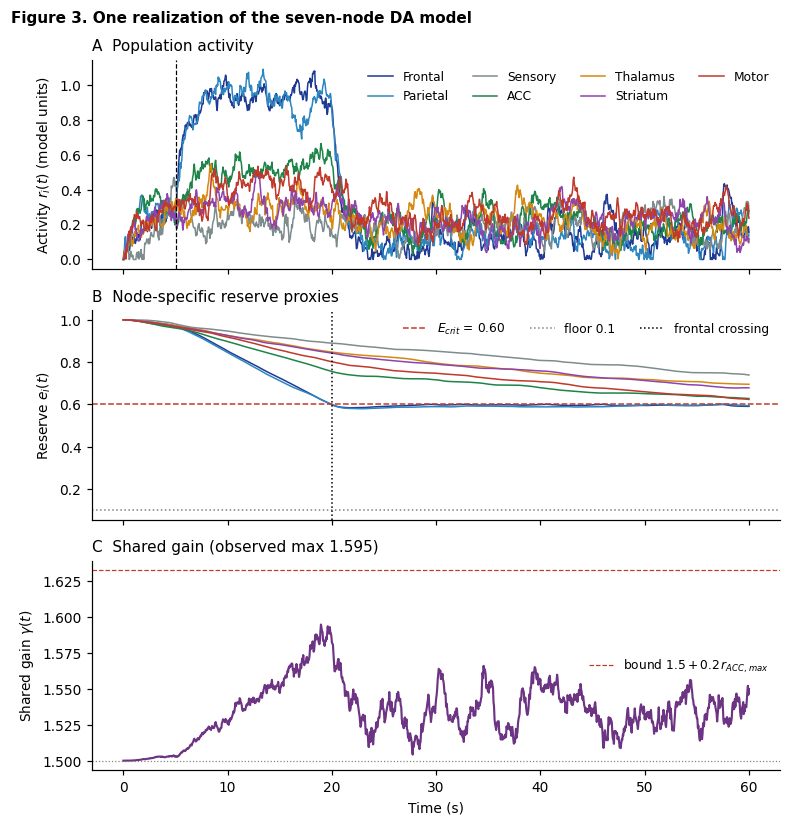

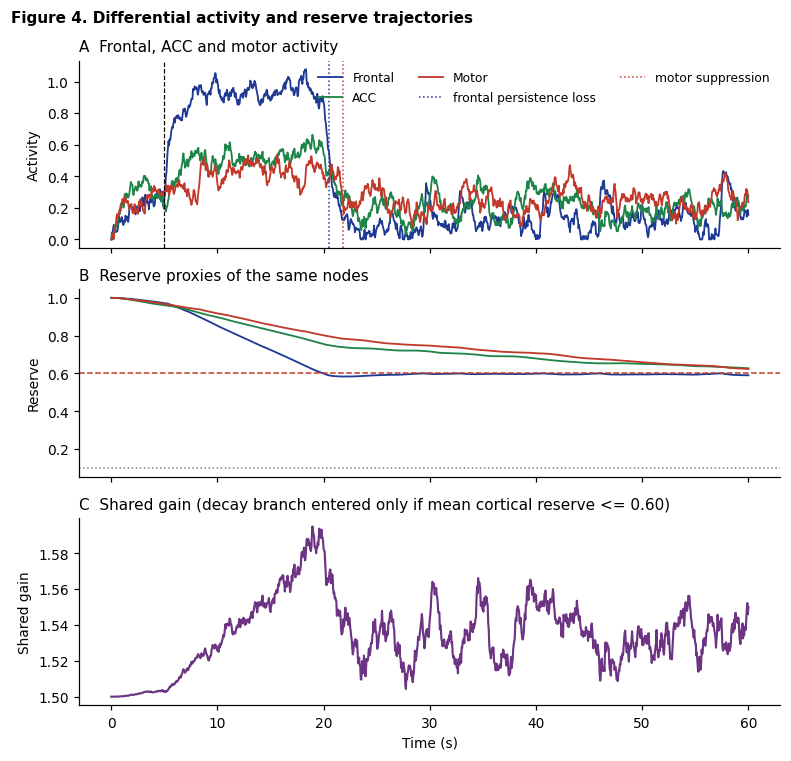

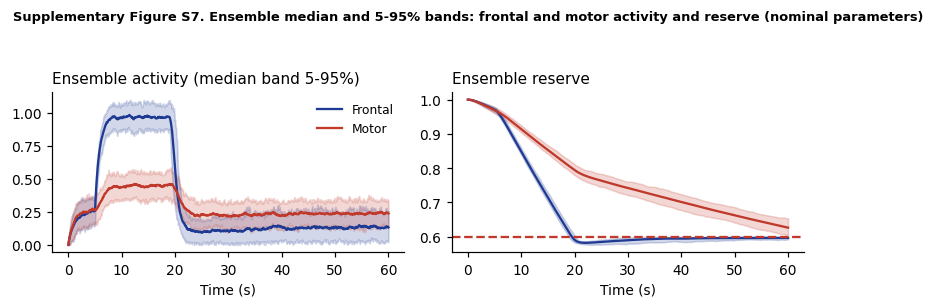

In [6]:
# ============ 4. Figures 3 and 4 ============
i = 0
ev_f = O0["frontal_cross_abs"][i]; ev_c = O0["cortical_cross_abs"][i]
ev_p = O0["persistence"][i] + P0["onset"]; ev_m = O0["motor_supp_after"][i] + P0["onset"]
ebar0 = e0[:,:,:3].mean(2)
print(f"Realization 0 | frontal crossing {ev_f:.2f} s | cortical crossing {ev_c} | frontal persistence loss {ev_p:.2f} s | "
      f"motor suppression {ev_m:.2f} s | max gain {g0[i].max():.4f} | gain-decay branch active steps: {int((ebar0[i] <= P0['Ecrit']).sum())}")

def vline(ax, x, c, lab):
    if x == x: ax.axvline(x, color=c, ls=":", lw=1, label=lab)

fig, ax = plt.subplots(3, 1, figsize=(7.2, 7.6), sharex=True)
for k in range(7): ax[0].plot(tvec, r0[i,:,k], color=NCOL[k], lw=1, label=NODES[k])
ax[0].axvline(P0["onset"], color="k", lw=0.8, ls="--"); ax[0].set_ylabel("Activity $r_i(t)$ (model units)")
ax[0].legend(ncol=4, frameon=False, loc="upper right"); ax[0].set_title("A  Population activity", loc="left")
for k in range(7): ax[1].plot(tvec, e0[i,:,k], color=NCOL[k], lw=1)
ax[1].axhline(P0["Ecrit"], color=C_THR, ls="--", lw=1, label="$E_{crit}$ = 0.60"); ax[1].axhline(0.1, color="grey", ls=":", lw=1, label="floor 0.1")
vline(ax[1], ev_f, "k", "frontal crossing"); ax[1].set_ylabel("Reserve $e_i(t)$"); ax[1].legend(frameon=False, ncol=3)
ax[1].set_title("B  Node-specific reserve proxies", loc="left")
ax[2].plot(tvec, g0[i], color=C_GAIN, lw=1.4); ax[2].axhline(1.5, color="grey", lw=0.8, ls=":")
ax[2].axhline(1.5+0.2*r0[i,:,3].max(), color=C_THR, lw=0.8, ls="--", label="bound $1.5+0.2\\,r_{ACC,max}$")
ax[2].set_ylabel("Shared gain $\\gamma(t)$"); ax[2].set_xlabel("Time (s)"); ax[2].legend(frameon=False)
ax[2].set_title(f"C  Shared gain (observed max {g0[i].max():.3f})", loc="left")
fig.suptitle("Figure 3. One realization of the seven-node DA model", x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); savefig(fig, "Figure3_representative_trajectory", "cell 4")

fig, ax = plt.subplots(3, 1, figsize=(7.2, 7.0), sharex=True)
for k in (0,3,6): ax[0].plot(tvec, r0[i,:,k], color=NCOL[k], lw=1.2, label=NODES[k])
vline(ax[0], ev_p, NCOL[0], "frontal persistence loss"); vline(ax[0], ev_m, NCOL[6], "motor suppression")
ax[0].axvline(P0["onset"], color="k", lw=0.8, ls="--"); ax[0].set_ylabel("Activity"); ax[0].legend(frameon=False, ncol=3, loc="upper right")
ax[0].set_title("A  Frontal, ACC and motor activity", loc="left")
for k in (0,3,6): ax[1].plot(tvec, e0[i,:,k], color=NCOL[k], lw=1.2)
ax[1].axhline(P0["Ecrit"], color=C_THR, ls="--", lw=1); ax[1].axhline(0.1, color="grey", ls=":", lw=1)
ax[1].set_ylabel("Reserve"); ax[1].set_title("B  Reserve proxies of the same nodes", loc="left")
ax[2].plot(tvec, g0[i], color=C_GAIN, lw=1.4); ax[2].set_ylabel("Shared gain"); ax[2].set_xlabel("Time (s)")
ax[2].set_title("C  Shared gain (decay branch entered only if mean cortical reserve <= 0.60)", loc="left")
fig.suptitle("Figure 4. Differential activity and reserve trajectories", x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); savefig(fig, "Figure4_differential_dynamics", "cell 4")

# ensemble view (supplementary): mean +/- 5-95% band of frontal and motor activity
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.8))
for k in (0, 6):
    ax[0].plot(tvec, r0[:,:,k].mean(0), color=NCOL[k], label=NODES[k])
    ax[0].fill_between(tvec, np.percentile(r0[:,:,k],5,axis=0), np.percentile(r0[:,:,k],95,axis=0), color=NCOL[k], alpha=0.2)
    ax[1].plot(tvec, e0[:,:,k].mean(0), color=NCOL[k])
    ax[1].fill_between(tvec, np.percentile(e0[:,:,k],5,axis=0), np.percentile(e0[:,:,k],95,axis=0), color=NCOL[k], alpha=0.2)
ax[1].axhline(P0["Ecrit"], color=C_THR, ls="--"); ax[0].legend(frameon=False)
ax[0].set_title("Ensemble activity (median band 5-95%)", loc="left"); ax[1].set_title("Ensemble reserve", loc="left")
for a_ in ax: a_.set_xlabel("Time (s)")
fig.suptitle("Supplementary Figure S7. Ensemble median and 5-95% bands: frontal and motor activity and reserve (nominal parameters)", x=0.01, ha="left", fontsize=8.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92)); savefig(fig, "FigureS7_ensemble_bands", "cell 4")

## 5. Sensitivity analysis (3.4), step-size check, and gain-branch stress test

Table 5. One-at-a-time sensitivity (same Brownian paths in every condition)

| Condition | Frontal cross (s after onset) | Cortical cross (s after onset) | Max gain | Persistence (s) | Motor suppr. (s after onset) | Median ratio 25-35 s |
|---|---|---|---|---|---|---|
| Nominal | 14.45 [13.95-15.20] (n=100) | n/a (n=0) | 1.59 [1.58-1.60] (n=100) | 15.00 [14.40-15.65] (n=100) | 17.12 [15.55-20.35] (n=100) | 2.13 [1.47-2.80] |
| alpha x0.8 | 14.23 [13.75-14.95] (n=100) | n/a (n=0) | 1.59 [1.58-1.60] (n=100) | 14.80 [14.20-15.41] (n=100) | 17.00 [15.20-19.83] (n=100) | 2.28 [1.51-3.29] |
| alpha x1.2 | 14.70 [14.20-15.45] (n=100) | n/a (n=0) | 1.59 [1.58-1.60] (n=100) | 15.28 [14.60-16.00] (n=100) | 17.33 [15.85-20.35] (n=100) | 1.76 [1.35-2.16] |
| beta x0.8 | 18.50 [17.95-19.25] (n=100) | n/a (n=0) | 1.59 [1.58-1.60] (n=100) | 19.05 [18.45-19.80] (n=100) | 21.08 [19.40-23.61] (n=100) | 1.87 [1.48-2.33] |
| beta x1.2 | 11.83 [11.30-12.40] (n=100) | n/a (n=0) | 1.59 [1.58-1.60] (n=100) | 


Table 6b. Entry into the gain-decay branch as depletion cost increases

| beta multiplier | runs with cortical-mean crossing | median time after onset (s) | median max gain |
|---|---|---|---|
| 1.0 | 0/100 | n/a | 1.592 |
| 1.5 | 88/100 | 46.08 [38.32-53.95] | 1.593 |
| 2.0 | 100/100 | 24.33 [20.65-29.31] | 1.593 |
| 2.5 | 100/100 | 14.90 [12.23-18.47] | 1.595 |
| 3.0 | 100/100 | 10.25 [8.20-13.31] | 1.599 |


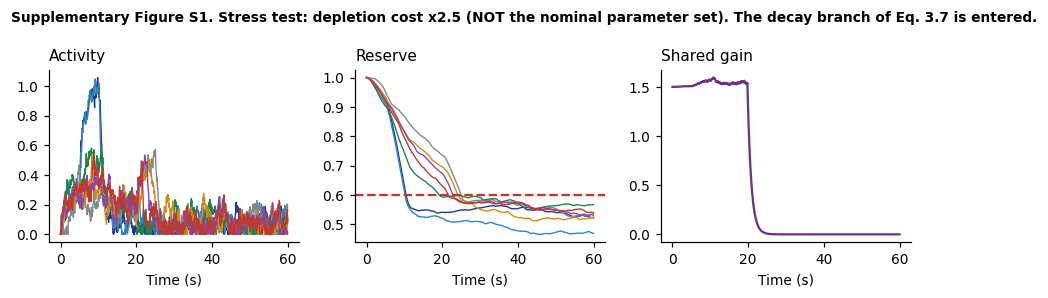

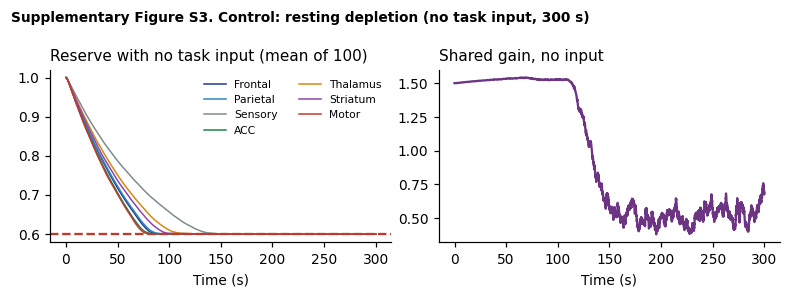

In [7]:
# ============ 5. Sensitivity, dt check, stress test ============
def run_condition(mod, label, dW=dW0, dt=0.05):
    p = default_params(); p.update(mod); p["dt"] = dt
    r, e, g = simulate(p, dW); o = outcomes(p, r, e, g)
    row = {"Condition":label}
    for k, short in [("frontal_cross_after","Frontal cross (s after onset)"),("cortical_cross_after","Cortical cross (s after onset)"),
                     ("max_gain","Max gain"),("persistence","Persistence (s)"),("motor_supp_after","Motor suppr. (s after onset)")]:
        n, s = summ(o[k]); row[short] = f"{s} (n={n})"
    row["Median ratio 25-35 s"] = summ(o["ratio_25_35"])[1]
    return row, o

conds = [("Nominal", {})]
for key, nm in [("alpha","alpha"),("beta","beta"),("Ecrit","E_crit"),("sigma","sigma"),("g0","gamma_0"),("Ag","A_gamma")]:
    for f in (0.8, 1.2): conds.append((f"{nm} x{f}", {key: default_params()[key]*f}))
for v in (0.94, 0.96): conds.append((f"decay factor {v}", {"dg": v}))
rows = []; SENS = {}
for lab, mod in conds:
    row, o = run_condition(mod, lab); rows.append(row); SENS[lab] = o
TS2 = pd.DataFrame(rows); savetable(TS2, "Table5_sensitivity_one_at_a_time", "cell 5")
print("Table 5. One-at-a-time sensitivity (same Brownian paths in every condition)\n"); print(md_table(TS2))

# order of crossings preserved across conditions? (frontal before cortical-mean)
pres = []
for lab, o in SENS.items():
    f, c = o["frontal_cross_abs"], o["cortical_cross_abs"]
    pres.append((lab, int((~np.isnan(f)).sum()), int((~np.isnan(c)).sum())))
print("\nRuns with frontal crossing / with cortical-mean crossing, per condition:"); [print("  ", x) for x in pres]

# ---- Delta t check (same Brownian path at 0.025 s; decay factor rescaled to keep tau_gamma fixed)
pfine = default_params(); pfine.update(dt=0.025, dg=0.95**0.5)
rf, ef, gf = simulate(pfine, dW_fine); Of = outcomes(pfine, rf, ef, gf)
rows = []
for k, lab in [("frontal_cross_after","Frontal crossing after onset (s)"),("max_gain","Max gain"),("persistence","Persistence (s)"),
               ("motor_supp_after","Motor suppression after onset (s)"),("ratio_25_35","Ratio 25-35 s")]:
    rows.append({"Outcome":lab, "dt = 0.05 s":summ(O0[k])[1], "dt = 0.025 s":summ(Of[k])[1]})
TS3 = pd.DataFrame(rows); savetable(TS3, "Table6_step_size_check", "cell 5")
print("\nTable 6. Step-size check\n"); print(md_table(TS3))

# ---- Stress test: how large must beta be for the gain-DECAY branch to be entered? (illustration of Eq. 2.10)
rows = []
for bm in [1.0, 1.5, 2.0, 2.5, 3.0]:
    p = default_params(); p["beta"] = 0.03*bm
    r, e, g = simulate(p, dW0); o = outcomes(p, r, e, g)
    n, s = summ(o["cortical_cross_after"])
    rows.append({"beta multiplier":bm, "runs with cortical-mean crossing":f"{n}/{N_REAL}", "median time after onset (s)":s,
                 "median max gain":f"{np.median(o['max_gain']):.3f}"})
TS4 = pd.DataFrame(rows); savetable(TS4, "Table6b_gain_branch_stress_test", "cell 5")
print("\nTable 6b. Entry into the gain-decay branch as depletion cost increases\n"); print(md_table(TS4))

pS = default_params(); pS["beta"] = 0.03*2.5
rS, eS, gS = simulate(pS, dW0); oS = outcomes(pS, rS, eS, gS)
fig, ax = plt.subplots(1, 3, figsize=(8.4, 2.7))
for k in range(7): ax[0].plot(tvec, rS[0,:,k], color=NCOL[k], lw=0.9)
for k in range(7): ax[1].plot(tvec, eS[0,:,k], color=NCOL[k], lw=0.9)
ax[1].axhline(0.6, color=C_THR, ls="--"); ax[2].plot(tvec, gS[0], color=C_GAIN)
ax[0].set_title("Activity", loc="left"); ax[1].set_title("Reserve", loc="left"); ax[2].set_title("Shared gain", loc="left")
for a_ in ax: a_.set_xlabel("Time (s)")
fig.suptitle("Supplementary Figure S1. Stress test: depletion cost x2.5 (NOT the nominal parameter set). The decay branch of Eq. 3.7 is entered.", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(); savefig(fig, "FigureS1_gain_branch_stress_test", "cell 5")

# ---- No-input control figure
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.7)); tc = np.arange(rc.shape[1])*Pc["dt"]
for k in range(7): ax[0].plot(tc, ec[:,:,k].mean(0), color=NCOL[k], lw=1, label=NODES[k])
ax[0].axhline(0.6, color=C_THR, ls="--"); ax[0].set_title("Reserve with no task input (mean of 100)", loc="left"); ax[0].set_xlabel("Time (s)")
ax[1].plot(tc, gc.mean(0), color=C_GAIN); ax[1].set_title("Shared gain, no input", loc="left"); ax[1].set_xlabel("Time (s)")
ax[0].legend(frameon=False, ncol=2, fontsize=7)
fig.suptitle("Supplementary Figure S3. Control: resting depletion (no task input, 300 s)", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(); savefig(fig, "FigureS3_no_input_control", "cell 5")

## 5b. Frozen-reserve stability analysis and the threshold-sliding regime (4.5)

This answers Reviewer 1, major comment 1, for the real seven-node model: with gate pattern and gain frozen, the deterministic network is a contraction (unique, globally stable equilibrium), so nothing in it can be called multistable. The abrupt changes seen in the time series are therefore parametric jumps of one equilibrium caused by the discontinuous gate, not attractor loss.

In [8]:
# ============ 5b. Stability analysis (frozen gate and gain) and sliding regime ============
from scipy.optimize import fsolve
Wm = make_W(); th1 = P0["theta"].copy(); tau_ = float(P0["tau"].max()); lam_task = np.asarray(P0["lam"], dtype=float).copy()
sig2 = np.linalg.svd(Wm, compute_uv=False)[0]; rho = max(abs(np.linalg.eigvals(Wm)))
print(f"||W||_2 = {sig2:.4f}, spectral radius = {rho:.4f}")
rows = []
for gam in (1.5, 1.7, 2.3):
    L = gam/4*sig2     # S' <= gamma/4 and gate <= 1, so F(r)=g*S(Wr+I) has Lipschitz constant <= gamma*||W||_2/4
    rows.append({"gamma":gam, "Lipschitz bound L = gamma*||W||_2/4":round(L,3), "contraction (L<1)":L < 1,
                 "guaranteed relaxation rate (1-L)/tau (1/s)":round((1-L)/tau_,2)})
TS6 = pd.DataFrame(rows); savetable(TS6, "TableS6_contraction_bound", "cell 5b")
print("\nContraction bound for the frozen-gate network (any gate pattern, any constant input)\n"); print(md_table(TS6))

def Ffix(r, gate, gam, I): return gate/(1.0 + np.exp(-gam*(Wm @ r + I - th1)))
def find_eq(gate, gam, I, nstart=12, rng=np.random.default_rng(0)):
    sols = []
    for _ in range(nstart):
        sol, info, ier, msg = fsolve(lambda r: -r + Ffix(r, gate, gam, I), rng.uniform(0, 1.5, 7), full_output=True)
        if ier == 1 and np.max(np.abs(-sol + Ffix(sol, gate, gam, I))) < 1e-9 and not any(np.allclose(sol, x, atol=1e-6) for x in sols):
            sols.append(sol)
    return sols
def max_re(r, gate, gam, I):
    u = Wm @ r + I; S = 1/(1+np.exp(-gam*(u - th1)))
    return np.linalg.eigvals((-np.eye(7) + np.diag(gate*gam*S*(1-S)) @ Wm)/tau_).real.max()

nmax, worst = 0, -1e9
for gam in (1.5, 1.7):
    for I in (lam_task, np.zeros(7)):
        for pat in itertools.product([1.0, 0.1], repeat=7):
            gate = np.array(pat); eq = find_eq(gate, gam, I); nmax = max(nmax, len(eq))
            for q in eq: worst = max(worst, max_re(q, gate, gam, I))
print(f"\nExhaustive check over all 128 gate patterns, gamma in (1.5, 1.7), task and rest: max number of equilibria found = {nmax}; "
      f"largest real part of any Jacobian eigenvalue = {worst:.3f} 1/s (all negative)")

pats = {"all gates open":np.ones(7), "frontal gated":np.array([.1,1,1,1,1,1,1]), "frontal+parietal gated":np.array([.1,.1,1,1,1,1,1])}
rows = []
for nm, gate in pats.items():
    q = find_eq(gate, 1.5, lam_task)[0]
    rows.append({"gate pattern (task on, gamma=1.5)":nm, **{n_: round(v, 3) for n_, v in zip(NODES, q)}, "max Re(lambda) (1/s)":round(max_re(q, gate, 1.5, lam_task), 3)})
q = find_eq(np.ones(7), 1.5, np.zeros(7))[0]
rows.append({"gate pattern (task on, gamma=1.5)":"rest (no input), gates open", **{n_: round(v, 3) for n_, v in zip(NODES, q)}, "max Re(lambda) (1/s)":round(max_re(q, np.ones(7), 1.5, np.zeros(7)), 3)})
TS7 = pd.DataFrame(rows); savetable(TS7, "Table7_frozen_reserve_equilibria", "cell 5b")
print("\nTable 7. The unique equilibrium for selected gate patterns\n"); print(md_table(TS7))
r_open, r_gated = rows[0]["Frontal"], rows[1]["Frontal"]

# ---- Threshold-sliding regime: mean-field prediction versus simulation (nominal ensemble)
f_pred = (0.01*(1-0.6)/0.03 - r_gated)/(r_open - r_gated)
fo, mr, me = [], [], []
for i_ in range(N_REAL):
    k = int(round(O0["frontal_cross_abs"][i_]/P0["dt"])) + int(10/P0["dt"])      # skip 10 s after first crossing
    fo.append(np.mean(e0[i_,k:,0] > P0["Ecrit"])); mr.append(r0[i_,k:,0].mean()); me.append(e0[i_,k:,0].mean())
print(f"\nSliding regime at E_crit: predicted gate-open fraction {f_pred:.3f}, predicted mean frontal activity {0.01*0.4/0.03:.4f}")
print(f"Simulated (ensemble mean, from 10 s after first crossing): gate-open fraction {np.mean(fo):.3f}, mean frontal activity {np.mean(mr):.3f}, mean frontal reserve {np.mean(me):.3f}")

# ---- Timescale separation
print(f"\nTimescales: activity relaxation <= {tau_/(1-0.492):.2f} s (contraction bound at gamma=1.5); reserve depletion 1/(beta*r) = {1/(0.03*0.75):.0f} s at r~0.75; recovery 1/alpha = 100 s")

||W||_2 = 1.3117, spectral radius = 0.9015

Contraction bound for the frozen-gate network (any gate pattern, any constant input)

| gamma | Lipschitz bound L = gamma*||W||_2/4 | contraction (L<1) | guaranteed relaxation rate (1-L)/tau (1/s) |
|---|---|---|---|
| 1.5 | 0.492 | True | 0.64 |
| 1.7 | 0.557 | True | 0.55 |
| 2.3 | 0.754 | True | 0.31 |



Exhaustive check over all 128 gate patterns, gamma in (1.5, 1.7), task and rest: max number of equilibria found = 1; largest real part of any Jacobian eigenvalue = -0.938 1/s (all negative)

Table 7. The unique equilibrium for selected gate patterns

| gate pattern (task on, gamma=1.5) | Frontal | Parietal | Sensory | ACC | Thalamus | Striatum | Motor | max Re(lambda) (1/s) |
|---|---|---|---|---|---|---|---|---|
| all gates open | 0.965 | 0.922 | 0.204 | 0.551 | 0.33 | 0.327 | 0.449 | -1.097 |
| frontal gated | 0.096 | 0.855 | 0.202 | 0.319 | 0.24 | 0.214 | 0.273 | -1.134 |
| frontal+parietal gated | 0.092 | 0.085 | 0.184 | 0.208 | 0.198 | 0.21 | 0.229 | -1.193 |
| rest (no input), gates open | 0.248 | 0.244 | 0.188 | 0.258 | 0.218 | 0.228 | 0.262 | -0.94 |

Sliding regime at E_crit: predicted gate-open fraction 0.043, predicted mean frontal activity 0.1333
Simulated (ensemble mean, from 10 s after first crossing): gate-open fraction 0.035, mean frontal activity 0.127, mean frontal r

## 5c. Analytic duty-cycle criterion for H3 (3.5, §4.6)

For block length b and rest s, the unconstrained reserve at the end of a block in the periodic regime is e1 = [E_on(1-x) + x(1-y)E_off]/(1-xy), with x = exp(-alpha*b), y = exp(-alpha*s), E = 1 - beta*r/alpha. The gate engages only if the reserve reaches E_crit, so e1 > E_crit predicts a schedule that never engages the gate.

In [9]:
# ============ 5c. Analytic duty-cycle criterion versus simulation ============
pDC = default_params(); pDC.update(theta=np.full(7,1.5), alpha=0.05, beta=0.06)
def eq_front(I, gate=np.ones(7)):
    W_ = pDC["W"]; th_ = pDC["theta"]
    q = fsolve(lambda r: -r + gate/(1+np.exp(-1.5*(W_ @ r + I - th_))), np.full(7, 0.3))
    return q[0]
ron, roff = eq_front(lam_task), eq_front(np.zeros(7)); a_, b_ = pDC["alpha"], pDC["beta"]
Eon, Eoff = 1 - b_*ron/a_, 1 - b_*roff/a_
print(f"Illustrative parameter set: frontal equilibrium activity task-on {ron:.3f}, rest {roff:.3f}; E_on = {Eon:.3f}, E_off = {Eoff:.3f}")
sched_list = [(24,1),(12,2),(6,4),(3,8)]
rows = []
for blk, nb in sched_list:
    x_, y_ = np.exp(-a_*blk), np.exp(-a_*20.0)
    first_end = Eon + (1 - Eon)*x_                                    # end of first block, starting from e = 1
    e1 = (Eon*(1-x_) + x_*(1-y_)*Eoff)/(1 - x_*y_)                    # end of block in the periodic regime (lower envelope)
    T_ = 5 + nb*blk + (nb-1)*20 + 5; pp = dict(pDC); pp["T"] = T_
    starts = [5 + k*(blk+20) for k in range(nb)]; sch = lambda t, st=starts, bb=blk: any(s0 <= t < s0+bb for s0 in st)
    rr, ee, gg = simulate(pp, brownian(N_REAL, T_, pp["dt"], 7), schedule=sch)
    engaged = float(np.mean(ee[:,:,0].min(1) <= pp["Ecrit"]))
    rows.append({"Block x n":f"{blk} x {nb}", "e at end of first block (pred.)":round(first_end,3), "e1 periodic (pred.)":round(e1,3),
                 "Predicted gate engagement":bool(min(first_end, e1) <= 0.6), "Fraction of simulated runs with frontal gate engaged":f"{engaged:.2f}"})
TS8 = pd.DataFrame(rows); savetable(TS8, "TableS8_duty_cycle_criterion", "cell 5c")
print("\nSupplementary Table S8. Analytic duty-cycle criterion versus simulation (illustrative parameters)\n"); print(md_table(TS8))

Illustrative parameter set: frontal equilibrium activity task-on 0.911, rest 0.112; E_on = -0.093, E_off = 0.865



Supplementary Table S8. Analytic duty-cycle criterion versus simulation (illustrative parameters)

| Block x n | e at end of first block (pred.) | e1 periodic (pred.) | Predicted gate engagement | Fraction of simulated runs with frontal gate engaged |
|---|---|---|---|---|
| 24 x 1 | 0.236 | 0.112 | True | 1.00 |
| 12 x 2 | 0.507 | 0.323 | True | 1.00 |
| 6 x 4 | 0.717 | 0.524 | True | 1.00 |
| 3 x 8 | 0.848 | 0.67 | False | 0.00 |


## 6. Reduced model (2.2, 4.7): Figure 2 and the reduced-model Figures 5 and 6 (reduced model only)

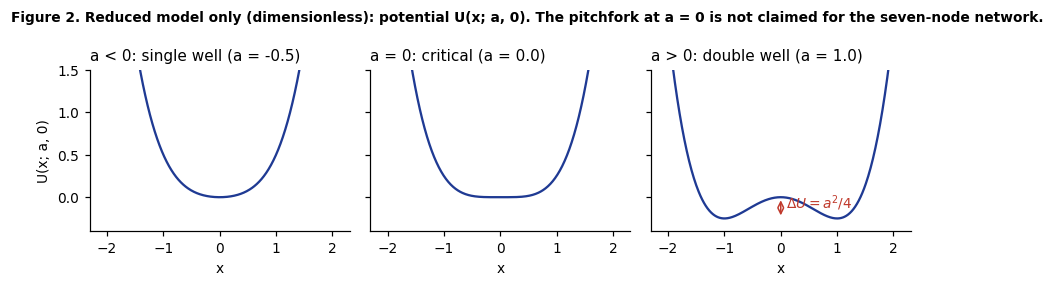

Table 9. Kramers verification (400 trajectories x 1500 time units each; SE across trajectories)

| a | D | Delta U / D | Simulated rate | Transitions | Kramers rate | Simulated / Kramers | Residence time 1/k |
|---|---|---|---|---|---|---|---|
| 1.5 | 0.15 | 3.75 | 0.00748 +/- 0.00011 | 4488 | 0.00794 | 94% | 126 |
| 1.2 | 0.15 | 2.4 | 0.02383 +/- 0.00021 | 14296 | 0.02450 | 97% | 41 |
| 1.5 | 0.2 | 2.81 | 0.01934 +/- 0.00019 | 11602 | 0.02028 | 95% | 49 |


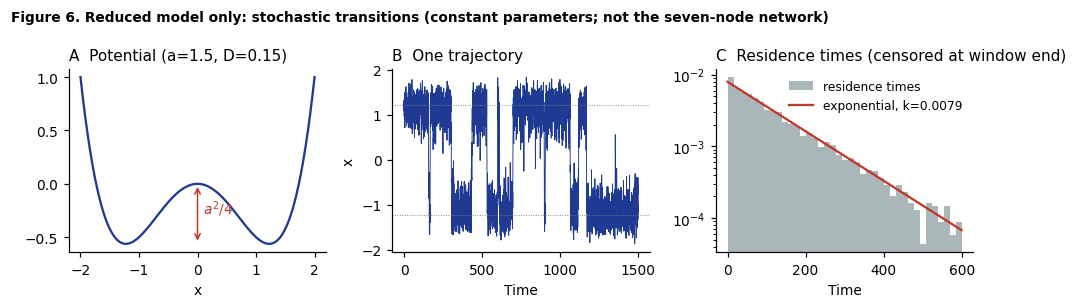

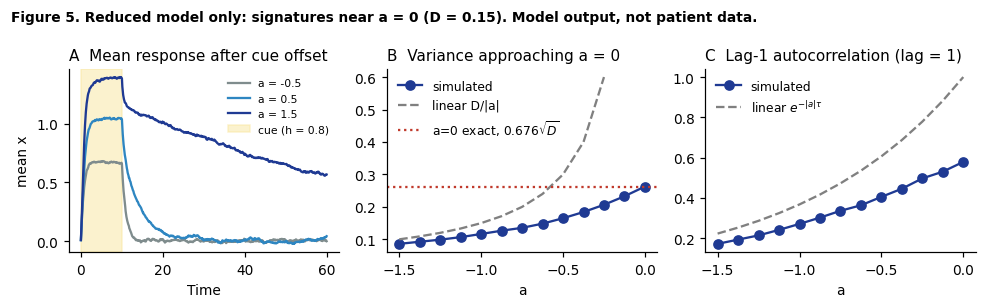

Variance at a = 0: simulated 0.2627 | exact 2*sqrt(D)*G(3/4)/G(1/4) = 0.2618


In [10]:
# ============ 6a. Figure 2: reduced potential ============
x = np.linspace(-2.1, 2.1, 400)
fig, ax = plt.subplots(1, 3, figsize=(8.4, 2.6), sharey=True)
for a_, a_val, ttl in zip(ax, [-0.5, 0.0, 1.0], ["a < 0: single well", "a = 0: critical", "a > 0: double well"]):
    U = x**4/4 - a_val*x**2/2; a_.plot(x, U, color="#1f3a93"); a_.set_title(f"{ttl} (a = {a_val})", loc="left"); a_.set_xlabel("x")
    if a_val > 0:
        a_.annotate("", xy=(0, -a_val**2/4), xytext=(0, 0), arrowprops=dict(arrowstyle="<->", color=C_THR))
        a_.text(0.1, -a_val**2/8, "$\\Delta U=a^2/4$", color=C_THR)
ax[0].set_ylabel("U(x; a, 0)"); ax[0].set_ylim(-0.4, 1.5)
fig.suptitle("Figure 2. Reduced model only (dimensionless): potential U(x; a, 0). The pitchfork at a = 0 is not claimed for the seven-node network.", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(); savefig(fig, "Figure2_reduced_potential", "cell 6a")

# ============ 6b. Kramers verification (Section 4.7) ============
def kramers(a, D): return sqrt(2)*a/(2*pi)*exp(-a*a/(4*D))

def kramers_sim(a, D, ntraj=400, T=1500.0, dt=0.01, seed=1, store=False):
    rng = np.random.default_rng(seed); n = int(round(T/dt)); thr = 0.5*np.sqrt(a)
    x = np.full(ntraj, np.sqrt(a)); state = np.ones(ntraj, int)
    ntrans = np.zeros(ntraj, int); last = np.zeros(ntraj); res = []; traj = []; sd = np.sqrt(2*D*dt)
    for k in range(n):
        x = x + (-x**3 + a*x)*dt + sd*rng.standard_normal(ntraj)
        ns = np.where(x > thr, 1, np.where(x < -thr, -1, state)); ch = ns != state
        if ch.any():
            tnow = (k+1)*dt
            for j in np.flatnonzero(ch): res.append(tnow - last[j]); last[j] = tnow
            ntrans += ch; state = ns
        if store and k % 20 == 0: traj.append(x[0])
    rates = ntrans/T
    return dict(rate=rates.mean(), se=rates.std(ddof=1)/np.sqrt(ntraj), total=int(ntrans.sum()),
                res=np.array(res), cens=T-last, traj=np.array(traj), dtr=dt*20, T=T)

rows = []; KR = {}
for a_, D_ in [(1.5, 0.15), (1.2, 0.15), (1.5, 0.20)]:
    kr = kramers_sim(a_, D_, store=(a_ == 1.5 and D_ == 0.15)); KR[(a_, D_)] = kr; kp = kramers(a_, D_)
    rows.append({"a":a_, "D":D_, "Delta U / D":round(a_*a_/4/D_,2), "Simulated rate":f"{kr['rate']:.5f} +/- {kr['se']:.5f}",
                 "Transitions":kr["total"], "Kramers rate":f"{kp:.5f}", "Simulated / Kramers":f"{100*kr['rate']/kp:.0f}%",
                 "Residence time 1/k":f"{1/kp:.0f}"})
T6 = pd.DataFrame(rows); savetable(T6, "Table9_reduced_model_Kramers", "cell 6b")
print("Table 9. Kramers verification (400 trajectories x 1500 time units each; SE across trajectories)\n"); print(md_table(T6))

kr = KR[(1.5, 0.15)]; a_, D_ = 1.5, 0.15
fig, ax = plt.subplots(1, 3, figsize=(9.0, 2.8))
xx = np.linspace(-2, 2, 400); ax[0].plot(xx, xx**4/4 - a_*xx**2/2, color="#1f3a93")
ax[0].annotate("", xy=(0, -a_**2/4), xytext=(0, 0), arrowprops=dict(arrowstyle="<->", color=C_THR))
ax[0].text(0.1, -a_**2/8, "$a^2/4$", color=C_THR); ax[0].set_title("A  Potential (a=1.5, D=0.15)", loc="left"); ax[0].set_xlabel("x")
ts = np.arange(len(kr["traj"]))*kr["dtr"]; ax[1].plot(ts, kr["traj"], color="#1f3a93", lw=0.6)
for s in (np.sqrt(a_), -np.sqrt(a_)): ax[1].axhline(s, color="grey", lw=0.6, ls=":")
ax[1].set_title("B  One trajectory", loc="left"); ax[1].set_xlabel("Time"); ax[1].set_ylabel("x")
res = kr["res"]; bins = np.linspace(0, min(res.max(), 600), 40); ax[2].hist(res, bins=bins, density=True, color="#aab7b8", label="residence times")
kp = kramers(a_, D_); tt = np.linspace(0, bins[-1], 200); ax[2].plot(tt, kp*np.exp(-kp*tt), color=C_THR, label=f"exponential, k={kp:.4f}")
ax[2].set_yscale("log"); ax[2].set_title("C  Residence times (censored at window end)", loc="left"); ax[2].set_xlabel("Time"); ax[2].legend(frameon=False)
fig.suptitle("Figure 6. Reduced model only: stochastic transitions (constant parameters; not the seven-node network)", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(); savefig(fig, "Figure6_reduced_model_transitions", "cell 6b")

# ============ 6c. Figure 8: reduced-model signatures ============
def fig8_data(D=0.15, seed=3, dt=0.01):
    rng = np.random.default_rng(seed); A = {}
    for a in [-0.5, 0.5, 1.5]:
        x = np.zeros(2000); tr = []
        for k in range(int(60/dt)):
            h = 0.8 if k*dt < 10 else 0.0
            x = x + (-x**3 + a*x + h)*dt + np.sqrt(2*D*dt)*rng.standard_normal(2000)
            if k % 10 == 0: tr.append(x.mean())
        A[a] = np.array(tr)
    avals = np.linspace(-1.5, 0.0, 13); var, ac = [], []
    for a in avals:
        x = np.zeros(300); rec = []
        for k in range(int(50/dt) + int(150/dt)):
            x = x + (-x**3 + a*x)*dt + np.sqrt(2*D*dt)*rng.standard_normal(300)
            if k >= int(50/dt) and (k - int(50/dt)) % 100 == 0: rec.append(x.copy())
        rec = np.array(rec); var.append(rec.var()); ac.append(np.mean(rec[:-1]*rec[1:])/rec.var())
    return A, avals, np.array(var), np.array(ac)

A8, av, var8, ac8 = fig8_data(); D = 0.15

# ---- Tables 8a / 8b (reduced model): persistence after cue; variance and autocorrelation near a = 0
rows = []
for a_, tr in A8.items():
    rows.append({"a": a_, "mean response at cue offset (t = 10)": round(float(tr[100]), 2) + 0.0,
                 "mean response at t = 60 (50 time units after offset)": round(float(tr[-1]), 2) + 0.0})
savetable(pd.DataFrame(rows), "Table8a_persistence_after_cue", "cell 6c")
Dv = 0.15; Vexact = 2*np.sqrt(Dv)*Gamma(.75)/Gamma(.25)
rows = [{"a": round(float(a_), 3), "simulated variance": round(float(v), 4),
         "linear D/|a|": (round(Dv/abs(a_), 4) if a_ < -0.2 else ""), "exact critical variance (a = 0)": (round(Vexact, 4) if abs(a_) < 1e-9 else ""),
         "simulated lag-1 autocorrelation": round(float(c_), 3), "linear exp(-|a|)": round(float(np.exp(-abs(a_))), 3)}
        for a_, v, c_ in zip(av, var8, ac8)]
savetable(pd.DataFrame(rows), "Table8b_variance_autocorrelation", "cell 6c")
fig, ax = plt.subplots(1, 3, figsize=(9.0, 2.8))
for (a, tr), c in zip(A8.items(), ["#7f8c8d", "#2e86c1", "#1f3a93"]):
    ax[0].plot(np.arange(len(tr))*0.1, tr, color=c, label=f"a = {a}")
ax[0].axvspan(0, 10, color="#f9e79f", alpha=0.5, label="cue (h = 0.8)"); ax[0].legend(frameon=False, fontsize=7, loc="upper right")
ax[0].set_title("A  Mean response after cue offset", loc="left"); ax[0].set_xlabel("Time"); ax[0].set_ylabel("mean x")
ax[1].plot(av, var8, "o-", color="#1f3a93", label="simulated"); ax[1].plot(av[av < -0.2], D/np.abs(av[av < -0.2]), "--", color="grey", label="linear D/|a|")
ax[1].axhline(2*np.sqrt(D)*Gamma(.75)/Gamma(.25), color=C_THR, ls=":", label="a=0 exact, 0.676$\\sqrt{D}$")
ax[1].set_title("B  Variance approaching a = 0", loc="left"); ax[1].set_xlabel("a"); ax[1].legend(frameon=False)
ax[2].plot(av, ac8, "o-", color="#1f3a93", label="simulated"); ax[2].plot(av, np.exp(-np.abs(av)), "--", color="grey", label="linear $e^{-|a|\\tau}$")
ax[2].set_title("C  Lag-1 autocorrelation (lag = 1)", loc="left"); ax[2].set_xlabel("a"); ax[2].legend(frameon=False)
fig.suptitle("Figure 5. Reduced model only: signatures near a = 0 (D = 0.15). Model output, not patient data.", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(); savefig(fig, "Figure5_reduced_model_signatures", "cell 6c")
print("Variance at a = 0: simulated", round(float(var8[-1]), 4), "| exact 2*sqrt(D)*G(3/4)/G(1/4) =", round(2*np.sqrt(D)*Gamma(.75)/Gamma(.25), 4))

## 7. Duty-cycle demonstration of Hypothesis 3 (Supplementary Figure S2)

This is a **model consequence**, not evidence. It uses an *illustrative parameter set* (θ = 1.5, α = 0.05) chosen so that reserve can recover during rest (see §3.5, resting activity). It is not the Table 2 parameter set and must be described that way.

Supplementary Table S5. Duty-cycle demonstration (total task time 24 s; 20 s rests; mean +/- SD over 100 runs)

| Configuration | Block (s) x n | Fraction of task time with frontal activity > 0.5 | Motor/frontal ratio |
|---|---|---|---|
| Persistence-limited | 24 x 1 | 0.42 +/- 0.02 | 0.33 |
| Persistence-limited | 12 x 2 | 0.63 +/- 0.03 | 0.30 |
| Persistence-limited | 6 x 4 | 0.96 +/- 0.02 | 0.25 |
| Persistence-limited | 3 x 8 | 1.00 +/- 0.00 | 0.23 |
| Propagation-limited | 24 x 1 | 1.00 +/- 0.00 | 0.13 |
| Propagation-limited | 12 x 2 | 1.00 +/- 0.00 | 0.14 |
| Propagation-limited | 6 x 4 | 1.00 +/- 0.00 | 0.14 |
| Propagation-limited | 3 x 8 | 1.00 +/- 0.00 | 0.14 |


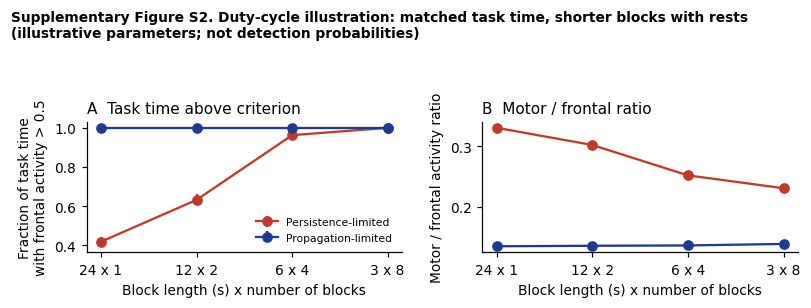

In [11]:
# ============ 7. Duty cycle (H3) ============
def run_duty(base_mod, block, nblocks, rest=20.0, N=100, seed=7, settle=1.5):
    p = default_params(); p.update(base_mod)
    T = 5 + nblocks*block + (nblocks-1)*rest + 5; p["T"] = T
    starts = [5 + k*(block + rest) for k in range(nblocks)]
    sched = lambda t: any(s0 <= t < s0 + block for s0 in starts)
    dW = brownian(N, T, p["dt"], seed); r, e, g = simulate(p, dW, schedule=sched)
    t = np.arange(r.shape[1])*p["dt"]; on = np.array([any(s0 + settle <= x < s0 + block for s0 in starts) for x in t])
    det = (r[:,on,0] > 0.5).mean(1)                    # fraction of settled task time with frontal activity > 0.5
    prop = r[:,on,6].mean(1)/np.maximum(r[:,on,0].mean(1), 1e-9)
    return det, prop

th15 = np.full(7, 1.5)
configs = {"Persistence-limited: depletion cost 0.06, alpha 0.05":
               dict(theta=th15, alpha=0.05, beta=0.06),
           "Propagation-limited: depletion cost 0.02, motor coupling x0.25":
               dict(theta=th15, alpha=0.05, beta=0.02, coupling_motor=0.25)}
sched_list = [(24,1),(12,2),(6,4),(3,8)]   # (block length s, number of blocks): total task time 24 s in every schedule
rows = []; DUTY = {}
for name, mod in configs.items():
    for blk, nb in sched_list:
        det, prop = run_duty(mod, blk, nb); DUTY[(name, blk)] = (det, prop)
        rows.append({"Configuration":name.split(":")[0], "Block (s) x n":f"{blk} x {nb}", "Fraction of task time with frontal activity > 0.5":f"{det.mean():.2f} +/- {det.std():.2f}",
                     "Motor/frontal ratio":f"{prop.mean():.2f}"})
TS5 = pd.DataFrame(rows); savetable(TS5, "TableS5_duty_cycle", "cell 7")
print("Supplementary Table S5. Duty-cycle demonstration (total task time 24 s; 20 s rests; mean +/- SD over 100 runs)\n"); print(md_table(TS5))

fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.8)); cols = ["#c0392b", "#1f3a93"]; blks = [b for b, _ in sched_list]
for (name, _), c in zip(configs.items(), cols):
    m = [DUTY[(name, b)][0].mean() for b in blks]; s = [DUTY[(name, b)][0].std() for b in blks]
    ax[0].errorbar(range(4), m, yerr=s, color=c, marker="o", label=name.split(":")[0])
    ax[1].plot(range(4), [DUTY[(name, b)][1].mean() for b in blks], color=c, marker="o")
for a_ in ax: a_.set_xticks(range(4)); a_.set_xticklabels(["24 x 1", "12 x 2", "6 x 4", "3 x 8"]); a_.set_xlabel("Block length (s) x number of blocks")
ax[0].set_ylabel("Fraction of task time\nwith frontal activity > 0.5"); ax[0].legend(frameon=False, fontsize=7); ax[1].set_ylabel("Motor / frontal activity ratio")
ax[0].set_title("A  Task time above criterion", loc="left"); ax[1].set_title("B  Motor / frontal ratio", loc="left")
fig.suptitle("Supplementary Figure S2. Duty-cycle illustration: matched task time, shorter blocks with rests\n(illustrative parameters; not detection probabilities)", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.88)); savefig(fig, "FigureS2_duty_cycle", "cell 7")

## 8. Conceptual schematics: Figures 1 and 7 (not simulation output)

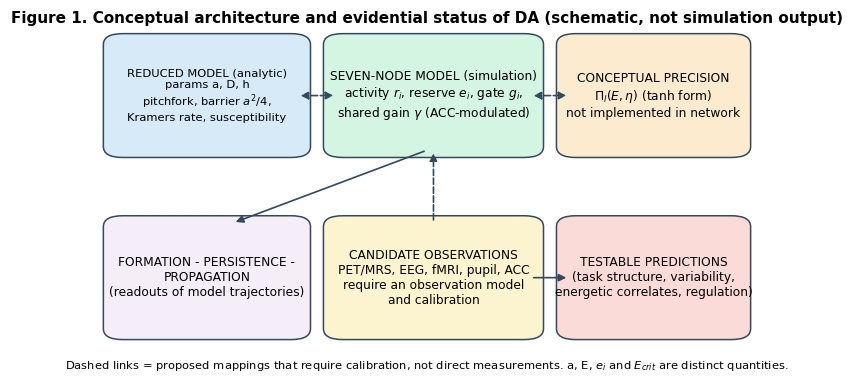

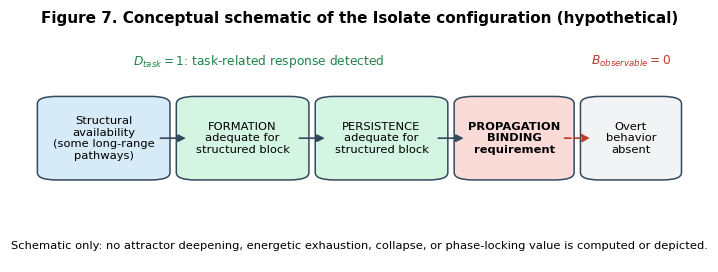

In [12]:
# ============ 8. Figures 1 and 5 ============
def box(ax, xy, w, h, text, fc, ec="#34495e", fs=8, bold=False):
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.03", fc=fc, ec=ec, lw=1))
    ax.text(xy[0]+w/2, xy[1]+h/2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", wrap=True)
def arrow(ax, p1, p2, style="-|>", ls="-", c="#34495e"):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle=style, mutation_scale=10, lw=1.1, ls=ls, color=c))

fig, ax = plt.subplots(figsize=(8.2, 4.3)); ax.set_xlim(-0.04, 1.04); ax.set_ylim(0, 1); ax.axis("off")
box(ax, (0.02, 0.62), 0.28, 0.30, "REDUCED MODEL (analytic)\nparams a, D, h\npitchfork, barrier $a^2/4$,\nKramers rate, susceptibility", "#d6eaf8", fs=7.5)
box(ax, (0.36, 0.62), 0.30, 0.30, "SEVEN-NODE MODEL (simulation)\nactivity $r_i$, reserve $e_i$, gate $g_i$,\nshared gain $\\gamma$ (ACC-modulated)", "#d5f5e3")
box(ax, (0.72, 0.62), 0.26, 0.30, "CONCEPTUAL PRECISION\n$\\Pi_l(E,\\eta)$ (tanh form)\nnot implemented in network", "#fdebd0")
box(ax, (0.02, 0.12), 0.28, 0.30, "FORMATION - PERSISTENCE -\nPROPAGATION\n(readouts of model trajectories)", "#f5eef8")
box(ax, (0.36, 0.12), 0.30, 0.30, "CANDIDATE OBSERVATIONS\nPET/MRS, EEG, fMRI, pupil, ACC\nrequire an observation model\nand calibration", "#fcf3cf")
box(ax, (0.72, 0.12), 0.26, 0.30, "TESTABLE PREDICTIONS\n(task structure, variability,\nenergetic correlates, regulation)", "#fadbd8")
arrow(ax, (0.30, 0.77), (0.36, 0.77), "<|-|>", "--"); arrow(ax, (0.66, 0.77), (0.72, 0.77), "<|-|>", "--")
arrow(ax, (0.50, 0.62), (0.20, 0.42)); arrow(ax, (0.51, 0.42), (0.51, 0.62), "-|>", "--"); arrow(ax, (0.66, 0.27), (0.72, 0.27))
ax.text(0.5, 0.97, "Figure 1. Conceptual architecture and evidential status of DA (schematic, not simulation output)", ha="center", fontsize=10, fontweight="bold")
ax.text(0.5, 0.02, "Dashed links = proposed mappings that require calibration, not direct measurements. a, E, $e_i$ and $E_{crit}$ are distinct quantities.", ha="center", fontsize=7.5)
savefig(fig, "Figure1_conceptual_architecture", "cell 8")

fig, ax = plt.subplots(figsize=(8.0, 2.9)); ax.set_xlim(-0.04, 1.04); ax.set_ylim(0, 1); ax.axis("off")
box(ax, (0.01, 0.35), 0.17, 0.30, "Structural\navailability\n(some long-range\npathways)", "#d6eaf8", fs=7.5)
box(ax, (0.23, 0.35), 0.17, 0.30, "FORMATION\nadequate for\nstructured block", "#d5f5e3", fs=7.5)
box(ax, (0.45, 0.35), 0.17, 0.30, "PERSISTENCE\nadequate for\nstructured block", "#d5f5e3", fs=7.5)
box(ax, (0.67, 0.35), 0.15, 0.30, "PROPAGATION\nBINDING\nrequirement", "#fadbd8", fs=7.5, bold=True)
box(ax, (0.87, 0.35), 0.12, 0.30, "Overt\nbehavior\nabsent", "#f2f3f4", fs=7.5)
for x0, x1 in [(0.18, 0.23), (0.40, 0.45), (0.62, 0.67)]: arrow(ax, (x0, 0.5), (x1, 0.5))
arrow(ax, (0.82, 0.5), (0.87, 0.5), ls="--", c=C_THR)
ax.text(0.34, 0.80, "$D_{task}=1$: task-related response detected", ha="center", fontsize=8, color="#1e8449")
ax.text(0.93, 0.80, "$B_{observable}=0$", ha="center", fontsize=8, color=C_THR)
ax.text(0.5, 0.97, "Figure 7. Conceptual schematic of the Isolate configuration (hypothetical)", ha="center", fontsize=10, fontweight="bold")
ax.text(0.5, 0.05, "Schematic only: no attractor deepening, energetic exhaustion, collapse, or phase-locking value is computed or depicted.", ha="center", fontsize=7.5)
savefig(fig, "Figure7_isolate_schematic", "cell 8")

## 9. Parameters, code checks, supplementary figures, manifest, and download

Supplementary Table S1a. Connectivity W (modeler-specified, not row-normalised)

                 source Frontal  source Parietal  source Sensory  source ACC  source Thalamus  source Striatum  source Motor
target Frontal              0.0              0.5             0.0         0.2              0.4              0.0           0.0
target Parietal             0.5              0.0             0.3         0.0              0.3              0.0           0.0
target Sensory              0.0              0.1             0.0         0.0              0.0              0.0           0.0
target ACC                  0.7              0.5             0.0         0.0              0.0              0.0           0.0
target Thalamus             0.3              0.2             0.0         0.1              0.0              0.0           0.0
target Striatum             0.4              0.0             0.0         0.0              0.4              0.0           0.0
target Motor                0.5             

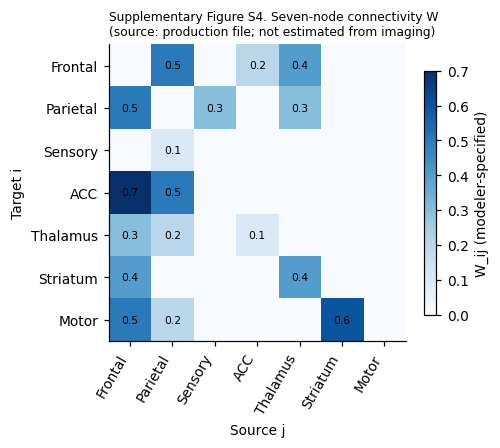

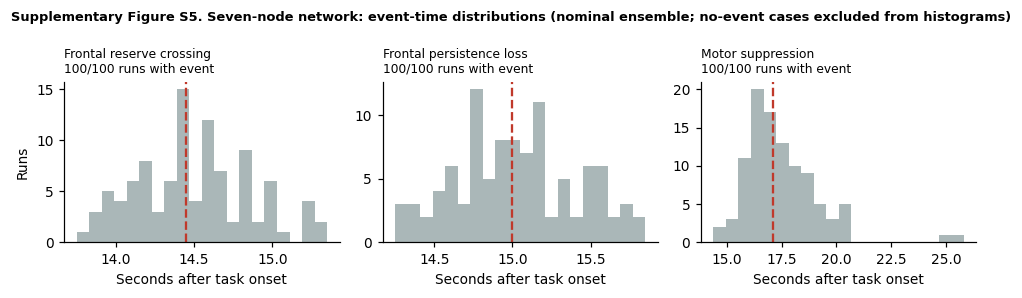

/tmp/ipykernel_13724/6176945.py:118: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[f"{a}-{b}" for a, b in WINDOWS], showfliers=False); ax.axhline(1, color="grey", ls=":")


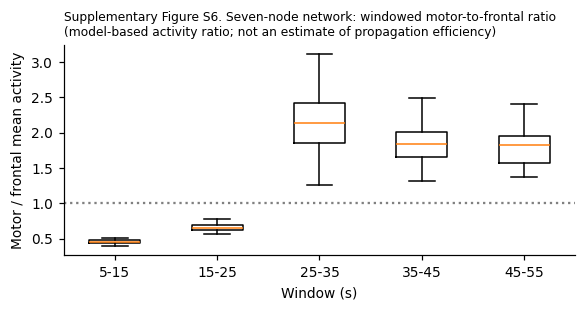

Wrote 21 sheets to Supplementary_Tables_all.xlsx

All outputs written to ./DA_outputs and zipped to ./DA_outputs.zip
(not running in Colab; zip is in the working directory)


In [13]:
# ============ 9. Table S1, manifest, zip ============
W = make_W(); Wdf = pd.DataFrame(W, index=[f"target {n}" for n in NODES], columns=[f"source {n}" for n in NODES]).round(2)
Wdf.to_csv(f"{OUT}/TableS1a_connectivity_W.csv"); SAVED.append(("TableS1a_connectivity_W.csv", "cell 9"))
par = pd.DataFrame({"node":NODES, "tau_i (s)":P0["tau"], "theta_i":P0["theta"], "task_input":P0["lam"]})
par = par.rename(columns={"tau_i (s)": "tau_i (s)", "theta_i": "theta_i"})
savetable(par, "TableS1b_tau_theta", "cell 9")
print("Supplementary Table S1a. Connectivity W (modeler-specified, not row-normalised)\n"); print(Wdf.to_string())
print("\nSupplementary Table S1b. tau and theta\n"); print(par.to_string(index=False))

# ---- Table 2: nominal parameters (modeler-specified, unfitted)
T2 = pd.DataFrame([
    ("alpha", P0["alpha"], "Reserve recovery coefficient (1/s); illustrative"),
    ("beta", P0["beta"], "Activity-dependent depletion coefficient; illustrative"),
    ("E_crit", P0["Ecrit"], "Operational gate and gain threshold; not physiologically calibrated"),
    ("Residual gate drive", P0["gate"], "Fraction of sigmoid drive retained below threshold"),
    ("Reserve floor", P0["floor"], "Numerical lower bound on each reserve variable"),
    ("sigma", P0["sigma"], "Additive activity-noise amplitude (units per sqrt(s))"),
    ("gamma_0 / A_gamma / decay factor", f'{P0["g0"]} / {P0["Ag"]} / {P0["dg"]} per {P0["dt"]} s', "Baseline gain, amplification coefficient, decay factor"),
    ("tau_i / theta_i", f'{P0["tau"][0]} s / {P0["theta"][0]} (see TableS1b for per-node values)', "Relaxation time and sigmoid threshold"),
    ("Direct task input", "; ".join(f"{node} {value:g}" for node, value in zip(NODES, P0["lam"])), "Node-specific values applied from onset to end of run"),
    ("Duration / step", f'{P0["T"]} s / {P0["dt"]} s', "Euler-Maruyama (activity) and forward Euler (reserve)"),
    ("Realizations", N_REAL, "Per condition; master seed " + str(MASTER_SEED)),
    ("Network input source", PROD["source"], "W, tau, theta, and task-input provenance"),
], columns=["Parameter", "Nominal value", "Interpretation and status"])
savetable(T2, "Table2_parameters", "cell 9")

# ---- Analytical properties and automated code checks
tg = -P0["dt"]/np.log(P0["dg"]); rstar = P0["alpha"]*(1-P0["Ecrit"])/P0["beta"]; rfloor = P0["alpha"]*(1-P0["floor"])/P0["beta"]
AP = [("Gain-decay time constant tau_gamma (s)", round(float(tg), 3), "tau_gamma = minus dt over ln(decay factor)"),
      ("Gain bound while amplification branch applies", "gamma < 1.5 + 0.20 * r_ACC,max", "because 1 - mean cortical reserve < 1 - E_crit"),
      ("Largest observed ACC activity (nominal ensemble)", round(float(O0["max_acc"].max()), 4), "ensemble"),
      ("Implied bound on gain at that ACC activity", round(float(1.5 + 0.20*O0["max_acc"].max()), 4), ""),
      ("Largest observed shared gain (nominal ensemble)", round(float(O0["max_gain"].max()), 4), ""),
      ("Critical activity r* = alpha(1-E_crit)/beta", round(float(rstar), 4), "reserve drift at E_crit is positive only below r*"),
      ("Activity above which reserve floor is active at equilibrium", round(float(rfloor), 3), "alpha(1-floor)/beta"),
      ("||W||_2", round(float(sig2), 4), "spectral norm"), ("Spectral radius of W", round(float(rho), 4), "")]
for _, row in TS6.iterrows():
    AP.append((f"Contraction bound L at gamma = {row['gamma']}", row["Lipschitz bound L = gamma*||W||_2/4"], "contraction if L < 1; applies to the frozen-gate activity subsystem only"))
savetable(pd.DataFrame(AP, columns=["Property", "Value", "Note"]), "TableA_analytical_properties", "cell 9")


# ---- Table 3b: the article's reference rows (constant-activity calculation vs observed median)
def tcross_from(r_, e_start, alpha=P0["alpha"], beta=P0["beta"], Ec=P0["Ecrit"]):
    eq = 1 - beta*r_/alpha; return -(1/alpha)*np.log((Ec - eq)/(e_start - eq)), eq
i5 = int(round(P0["onset"]/P0["dt"])); e_onset = float(e0[:, i5, 0].mean())
med_abs = float(np.nanmedian(O0["frontal_cross_abs"])); i_med = int(round(med_abs/P0["dt"]))
r_mean_to_cross = float(r0[:, i5:i_med, 0].mean())
rows = []
for lab, r_, e_s in [(f"Open-gate frontal activity {r_open:.3f}, starting from mean onset reserve {e_onset:.3f}", r_open, e_onset),
                     (f"Same activity, starting from reserve 1.000", r_open, 1.0),
                     (f"Mean frontal activity from task onset to median crossing ({r_mean_to_cross:.3f}), starting at reserve {e_onset:.3f}", r_mean_to_cross, e_onset)]:
    tc, eq_ = tcross_from(r_, e_s)
    rows.append({"Reference calculation": lab, "Unconstrained equilibrium e*": round(eq_, 3), "Predicted crossing after onset (s)": round(tc, 2),
                 "Predicted crossing, absolute (s)": round(tc + P0["onset"], 2), "Observed median after onset (s)": round(float(np.nanmedian(O0["frontal_cross_after"])), 2),
                 "Observed median, absolute (s)": round(med_abs, 2)})
savetable(pd.DataFrame(rows), "Table3b_reference_vs_observed", "cell 9")

# ---- TableA_text_values: every in-text number that is not in another table
TV = []
def tv(q, v, where): TV.append({"quantity": q, "value": v, "article location": where})
tv("Mean frontal activity at t = 4.9 s (ensemble)", round(float(r_rest[0]), 3), "Section 3.3")
for nm_, k_ in [("frontal", 0), ("parietal", 1), ("sensory", 2)]: tv(f"Ensemble-mean {nm_} reserve at 60 s", round(float(e0[:, -1, k_].mean()), 3), "Section 4.2")
tv("Ensemble-mean three-node cortical reserve at 60 s", round(float(e0[:, -1, :3].mean()), 3), "Section 4.2")
fa = O0["frontal_cross_after"]; tv("SD of frontal crossing time after onset (population SD, ddof = 0)", round(float(np.nanstd(fa, ddof=0)), 2), "Section 4.2")
tv("Runs with both persistence loss and motor suppression", int(both.sum()), "Section 4.4")
tv("Motor suppression after frontal persistence loss (runs)", int((d > 0).sum()), "Section 4.4"); tv("Motor suppression before frontal persistence loss (runs)", int((d < 0).sum()), "Section 4.4")
tv("Paired difference median [5th-95th] (s)", f"{np.median(d):.2f} [{np.percentile(d,5):.2f}-{np.percentile(d,95):.2f}]", "Section 4.4")
tv("ACC activity needed for gain 2.3 under Eq. 3.7 (upper bound)", round((2.3 - 1.5)/0.2, 1), "Section 4.2")
tv("Closed-gate motor-to-frontal ratio (frozen gate)", round(float(TS7["Motor"].iloc[1]/TS7["Frontal"].iloc[1]), 2), "Section 4.4")
tv("Representative run: frontal crossing (abs s)", float(ev_f), "Section 4.4"); tv("Representative run: persistence loss (abs s)", round(float(ev_p), 2), "Section 4.4")
tv("Representative run: motor suppression (abs s)", round(float(ev_m), 2), "Section 4.4"); tv("Representative run: max gain", round(float(g0[0].max()), 3), "Section 4.4")
tv("Representative run: gain-decay steps", int((ebar0[0] <= P0["Ecrit"]).sum()), "Section 4.4")
tv("Frozen-gate equilibria searched: max number found", int(nmax), "Section 4.5"); tv("Largest real part of Jacobian eigenvalue (1/s)", round(float(worst), 3), "Section 4.5")
tv("Predicted open-gate fraction (Eq. 3.14)", round(float(f_pred), 3), "Section 4.5"); tv("Simulated open-gate fraction", round(float(np.mean(fo)), 3), "Section 4.5")
tv("Mean frontal activity, 10 s after first crossing", round(float(np.mean(mr)), 3), "Section 4.5"); tv("Mean frontal reserve, 10 s after first crossing", round(float(np.mean(me)), 3), "Section 4.5")
tv("No-input control: frontal crossing median [5th-95th] (events)", f"{summ(ctrl_f)[1]} ({summ(ctrl_f)[0]})", "Section 4.3"); tv("No-input control: cortical-mean crossing", f"{summ(ctrl_c)[1]} ({summ(ctrl_c)[0]})", "Section 4.3")
tv("No-input control: frontal crossings in first 60 s", int((ctrl_f <= 60).sum()), "Section 4.3")
tv("Duty-cycle task-on / rest equilibrium frontal activity", f"{ron:.3f} / {roff:.3f}", "Section 3.7"); tv("Duty-cycle unconstrained reserve equilibria e*on / e*off", f"{Eon:.3f} / {Eoff:.3f}", "Section 3.7")
savetable(pd.DataFrame(TV), "TableA_text_values", "cell 9")

check("Activity non-negative (clipped at zero)", r0.min() >= 0)
check("Reserve respects floor", e0.min() >= P0["floor"] - 1e-12, f"min reserve {e0.min():.3f}")
check("Initial conditions and seven-node task-input vector are valid", np.all(r0[:,0,:] == 0) and np.all(e0[:,0,:] == 1) and np.allclose(g0[:,0], 1.5) and np.asarray(P0["lam"]).shape == (7,) and np.isfinite(P0["lam"]).all(), f"task_input={np.asarray(P0['lam']).tolist()}")
check("Coarse Brownian increment = sum of two fine increments", np.allclose(dW0[:,0,:], dW_fine[:,0,:] + dW_fine[:,1,:]))
check("Gain bound holds in every run", bool(np.all(O0["max_gain"] <= 1.5 + 0.20*O0["max_acc"] + 1e-12)))
check("Table 3: analytic vs numeric crossing agree (max |diff| < 0.05 s)", float(T3["abs_diff_s"].max()) < 0.05, f"max {float(T3['abs_diff_s'].max())}")
check("Frozen-gate contraction at gamma = 1.5 (L < 1)", float(TS6["Lipschitz bound L = gamma*||W||_2/4"].iloc[0]) < 1)
check("Kramers: simulated rate within 90-100% of analytic in all 3 settings", all(0.90 <= KR[k]["rate"]/kramers(*k) <= 1.0 for k in KR))
check("Reduced model: critical variance within 2% of exact", abs(float(var8[-1]) - Vexact) / Vexact < 0.02, f"{float(var8[-1]):.4f} vs {Vexact:.4f}")
Wc = make_W()
check("W matches manuscript: row sums 0.1 (sensory) and 1.3 (motor)", np.isclose(Wc[2].sum(), 0.1, atol=1e-6) and np.isclose(Wc[6].sum(), 1.3, atol=1e-6), f"{Wc[2].sum():.3f}, {Wc[6].sum():.3f}")
check("W matches manuscript: ||W||_2 = 1.3117 and spectral radius 0.9015", np.isclose(sig2, 1.3117, atol=1e-3) and np.isclose(rho, 0.9015, atol=1e-3), f"{sig2:.4f}, {rho:.4f}")
check("Manuscript headline: frontal reserve crosses in 100/100 runs", int((~np.isnan(O0["frontal_cross_abs"])).sum()) == N_REAL)
check("Manuscript headline: mean cortical reserve never crosses (nominal)", int((~np.isnan(O0["cortical_cross_abs"])).sum()) == 0)
savetable(pd.DataFrame(CHECKS), "TableA_code_checks", "cell 9")

# ---- Supplementary figures from the current network inputs
fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.imshow(Wc, cmap="Blues", vmin=0); ax.set_xticks(range(7)); ax.set_yticks(range(7)); ax.set_xticklabels(NODES, rotation=60, ha="right"); ax.set_yticklabels(NODES)
ax.set_xlabel("Source j"); ax.set_ylabel("Target i")
for ii in range(7):
    for jj in range(7):
        if Wc[ii, jj] != 0: ax.text(jj, ii, f"{Wc[ii, jj]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="W_ij (modeler-specified)")
ax.set_title("Supplementary Figure S4. Seven-node connectivity W\n(source: " + ("production file" if PROD["W"] is not None else "built-in default") + "; not estimated from imaging)", fontsize=8, loc="left")
fig.tight_layout(); savefig(fig, "FigureS4_connectivity_matrix", "cell 9")

fig, ax = plt.subplots(1, 3, figsize=(9.0, 2.7))
for a_, (k, lab) in zip(ax, [("frontal_cross_after", "Frontal reserve crossing"), ("persistence", "Frontal persistence loss"), ("motor_supp_after", "Motor suppression")]):
    v = O0[k][~np.isnan(O0[k])]; a_.hist(v, bins=20, color="#aab7b8"); a_.axvline(np.median(v), color=C_THR, ls="--")
    a_.set_title(f"{lab}\n{len(v)}/{N_REAL} runs with event", fontsize=8, loc="left"); a_.set_xlabel("Seconds after task onset")
ax[0].set_ylabel("Runs")
fig.suptitle("Supplementary Figure S5. Seven-node network: event-time distributions (nominal ensemble; no-event cases excluded from histograms)", x=0.01, ha="left", fontsize=8.5, fontweight="bold")
fig.tight_layout(); savefig(fig, "FigureS5_event_time_distributions", "cell 9")

fig, ax = plt.subplots(figsize=(5.4, 2.9))
data = [O0[f"ratio_{a}_{b}"][~np.isnan(O0[f"ratio_{a}_{b}"])] for a, b in WINDOWS]
ax.boxplot(data, labels=[f"{a}-{b}" for a, b in WINDOWS], showfliers=False); ax.axhline(1, color="grey", ls=":")
ax.set_xlabel("Window (s)"); ax.set_ylabel("Motor / frontal mean activity")
ax.set_title("Supplementary Figure S6. Seven-node network: windowed motor-to-frontal ratio\n(model-based activity ratio; not an estimate of propagation efficiency)", fontsize=8, loc="left")
fig.tight_layout(); savefig(fig, "FigureS6_windowed_ratios", "cell 9")

# ---- One Excel workbook with every table (typed cells, so Excel does not reinterpret text as dates)
import glob
_csvs = sorted(glob.glob(f"{OUT}/*.csv")); _idx = []
with pd.ExcelWriter(f"{OUT}/Supplementary_Tables_all.xlsx", engine="openpyxl") as xw:
    for f_ in _csvs:
        base = os.path.basename(f_)[:-4]; sheet = base[:31]
        pd.read_csv(f_).to_excel(xw, sheet_name=sheet, index=False); _idx.append({"sheet": sheet, "source csv": base + ".csv"})
    pd.DataFrame(_idx).to_excel(xw, sheet_name="INDEX", index=False)
SAVED.append(("Supplementary_Tables_all.xlsx", "cell 9"))
print("Wrote", len(_csvs), "sheets to Supplementary_Tables_all.xlsx")

import sys, scipy, openpyxl
manifest = {"master_seed":MASTER_SEED, "n_realizations":N_REAL, "representative_realization_index":0,
            "dt":0.05, "dt_check":0.025, "network_input_source":PROD["source"],
            "environment": {"python":sys.version.split()[0], "numpy":np.__version__, "pandas":pd.__version__,
                            "scipy":scipy.__version__, "matplotlib":matplotlib.__version__, "openpyxl":openpyxl.__version__},
            "files":[{"file":f, "generated_in":c, "role":("main" if re.match(r"(Figure[1-7]_|Table2_|Table3|Table4_)", f) else "supplementary")} for f, c in SAVED],
            "reduced_model_seed_note":"Kramers simulation seed 1; Figure 5 seed 3; duty-cycle seed 7"}
json.dump(manifest, open(f"{OUT}/MANIFEST.json", "w"), indent=2)
with zipfile.ZipFile(f"{OUT}.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(OUT)): z.write(f"{OUT}/{fn}", fn)
print("\nAll outputs written to", OUT, "and zipped to", OUT + ".zip")
try:
    from google.colab import files; files.download(OUT + ".zip")
except Exception as ex:
    print("(not running in Colab; zip is in the working directory)")